# MARACOOS totals: measured accuracy and coverage

This notebook displays a reproducible comparison of production UWLS/OI with the proposed OI time window, parameter,
and QC changes. It distinguishes **predicting withheld radar observations**, **recovering hidden daily values**, and
**validating against independent current measurements**. A passing software test or a smoother map does not establish
better current accuracy.

Expensive work runs in `examples/maracoos_study.py`; analysis lives in `examples/maracoos_study_analysis.py`.
Per-hour and per-site checkpoints are isolated by input/code fingerprint and written atomically. WLS and EHN algorithms
are unchanged. The original exploratory notebook was preserved under the output directory.

## 1. Reproduce or inspect the completed study

Leave `RUN_STUDY=False` to open the saved results immediately. Set it to `True` to resume/recompute. Each input file,
grid, mask, configuration, numerical source and dependency version is recorded. Changing inputs or compute code creates
a separate run. A different dependency environment must use a new output directory.

Only October 6–12 is currently available. No parameters are tuned here. An additional week and independent buoy/drifter
currents remain pending unless supplied; they cannot be replaced by more tests on this week.

In [1]:
import json
import subprocess
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'hfradarpy/totals.py').exists())
EXAMPLES = ROOT / 'examples'
OUTPUT = EXAMPLES / 'output/maracoos_totals_study'
DATA = Path('~/Documents/hfradar_parity/2026-10-06_week').expanduser()
START, END = '2026-10-06T00:00', '2026-10-12T23:00'
RUN_STUDY = False
INSITU_FILE = None  # optional quality-controlled CSV: time, lon, lat, u, v
INSITU_UNITS = 'cm/s'  # explicitly choose 'm/s' if appropriate

if RUN_STUDY:
    command = [sys.executable, str(EXAMPLES / 'maracoos_study.py'), '--data', str(DATA),
               '--start', START, '--end', END, '--output', str(OUTPUT), '--loso-step', '6']
    if INSITU_FILE:
        command += ['--insitu-file', str(INSITU_FILE), '--insitu-units', INSITU_UNITS]
    subprocess.run(command, cwd=ROOT, check=True)

latest = OUTPUT / 'latest.json'
if not latest.exists():
    raise RuntimeError('No study has run yet. Set RUN_STUDY=True.')
RUN = Path(json.loads(latest.read_text())['run'])
if not (RUN / 'analysis_complete.json').exists():
    raise RuntimeError(f'Study is incomplete: {RUN}. Resume with RUN_STUDY=True.')
manifest = json.loads((RUN / 'manifest.json').read_text())
print('Results:', RUN)
print('Period:', manifest['start'], 'through', manifest['end'])
print('Input radial files:', len(manifest['radial_sha256']))
print('LOSO sampling interval (hours):', manifest['loso_step_hours'])
print('Fingerprint:', manifest['fingerprint'])

def table(name, **kwargs):
    return pd.read_csv(RUN / 'tables' / f'{name}.csv', **kwargs)

def figure(name):
    display(Image(filename=str(RUN / 'figures' / f'{name}.png')))


Results: /Users/mikesmith/Documents/github/HFRadarPy/examples/output/maracoos_totals_study/3dc6274a28e6d79b
Period: 2026-10-06 00:00:00 through 2026-10-12 23:00:00
Input radial files: 2144
LOSO sampling interval (hours): 6
Fingerprint: 3dc6274a28e6d79be7c7eebc266bef1b4c594fd1fa1961fe483346ef8aba70ae


## 2. Configurations and baseline fidelity

The uncertainty limit of 0.7 is **less restrictive** than production's 0.6. The site-share limit is evaluated separately.
The centered window uses radials from t−1, t and t+1 and therefore needs one additional hour of input availability.

The parameter candidates are informed by [Nwankwo et al. (2026)](https://doi.org/10.1007/s10236-026-01813-8).
625 and 100 are used as squared-cm/s variances, following the original notebook's native radial units. The publication
labels these numbers m²/s²; this study records its assumption rather than treating that discrepancy as resolved.

In [2]:
rows=[]
for key, c in manifest['configurations'].items():
    for name, (uncertainty, share) in c['outputs'].items():
        oi=c.get('oi', {})
        rows.append({'configuration':name, 'method':c['method'], 'window hours':c['window'],
                     'model variance':oi.get('mdlvar'), 'error variance':oi.get('errvar'),
                     'sx km':oi.get('sx'), 'sy km':oi.get('sy'),
                     'uncertainty limit':uncertainty if uncertainty is not None else (0.6 if oi else None),
                     'max site share':share})
display(pd.DataFrame(rows).set_index('configuration'))
parity=table('production_parity')
display(parity.groupby('variable')[['paired','missing_mismatches','different','max_abs_difference']]
        .agg({'paired':'sum','missing_mismatches':'sum','different':'sum','max_abs_difference':'max'}))
print('Velocity comparisons use production float32/whole-cm/s rounding, with no QC-pass filtering.')

,method,window hours,model variance,error variance,sx km,sy km,uncertainty limit,max site share
configuration,,,,,,,,
UWLS production,uwls,0,NaN,NaN,NaN,NaN,NaN,NaN
OI production,oi,0,420.0,66.0,15.0,15.0,0.6,NaN
OI production + window,oi,1,420.0,66.0,15.0,15.0,0.6,NaN
OI Nwankwo parameters,oi,0,625.0,100.0,10.0,10.0,0.6,NaN
OI Nwankwo parameters + window,oi,1,625.0,100.0,10.0,10.0,0.6,NaN
OI Nwankwo + uncertainty QC,oi,1,625.0,100.0,10.0,10.0,0.7,NaN
OI Nwankwo + site QC,oi,1,625.0,100.0,10.0,10.0,0.6,0.75
Nwankwo (full),oi,1,625.0,100.0,10.0,10.0,0.7,0.75


,paired,missing_mismatches,different,max_abs_difference
variable,,,,
qc_primary_flag,2538648,0,0,0.0
u,973669,0,0,0.0
v,973669,0,0,0.0


Velocity comparisons use production float32/whole-cm/s rounding, with no QC-pass filtering.


## 3. Accuracy versus coverage: withheld radar sites

Each site is removed from **all hours** of the input window. Totals from the other sites predict its cleaned radial
velocities using u sin(HEAD) + v cos(HEAD), at the nearest grid point within 4.3 km.

The accuracy plot uses only bins predicted by **every configuration**. Coverage counts every eligible withheld bin,
including those no configuration predicts. These are radar-to-radar comparisons, not independent ground truth.

,eligible_bins,predicted_bins,coverage_pct,all_common_bins,all_common_rmse_cm_s,bias_cm_s,median_abs_error_cm_s
config,,,,,,,
UWLS production,180599,69671,38.578,54897,12.857,-0.156,7.855
OI production,180599,78040,43.212,54897,12.832,0.018,8.083
OI production + window,180599,89991,49.829,54897,12.845,-0.014,8.347
OI Nwankwo parameters,180599,60474,33.485,54897,12.723,0.148,7.789
OI Nwankwo parameters + window,180599,73086,40.469,54897,12.759,0.067,7.980
OI Nwankwo + uncertainty QC,180599,85258,47.208,54897,12.759,0.156,8.181
OI Nwankwo + site QC,180599,64928,35.951,54897,12.759,0.022,7.794
Nwankwo (full),180599,71727,39.716,54897,12.759,-0.006,7.918


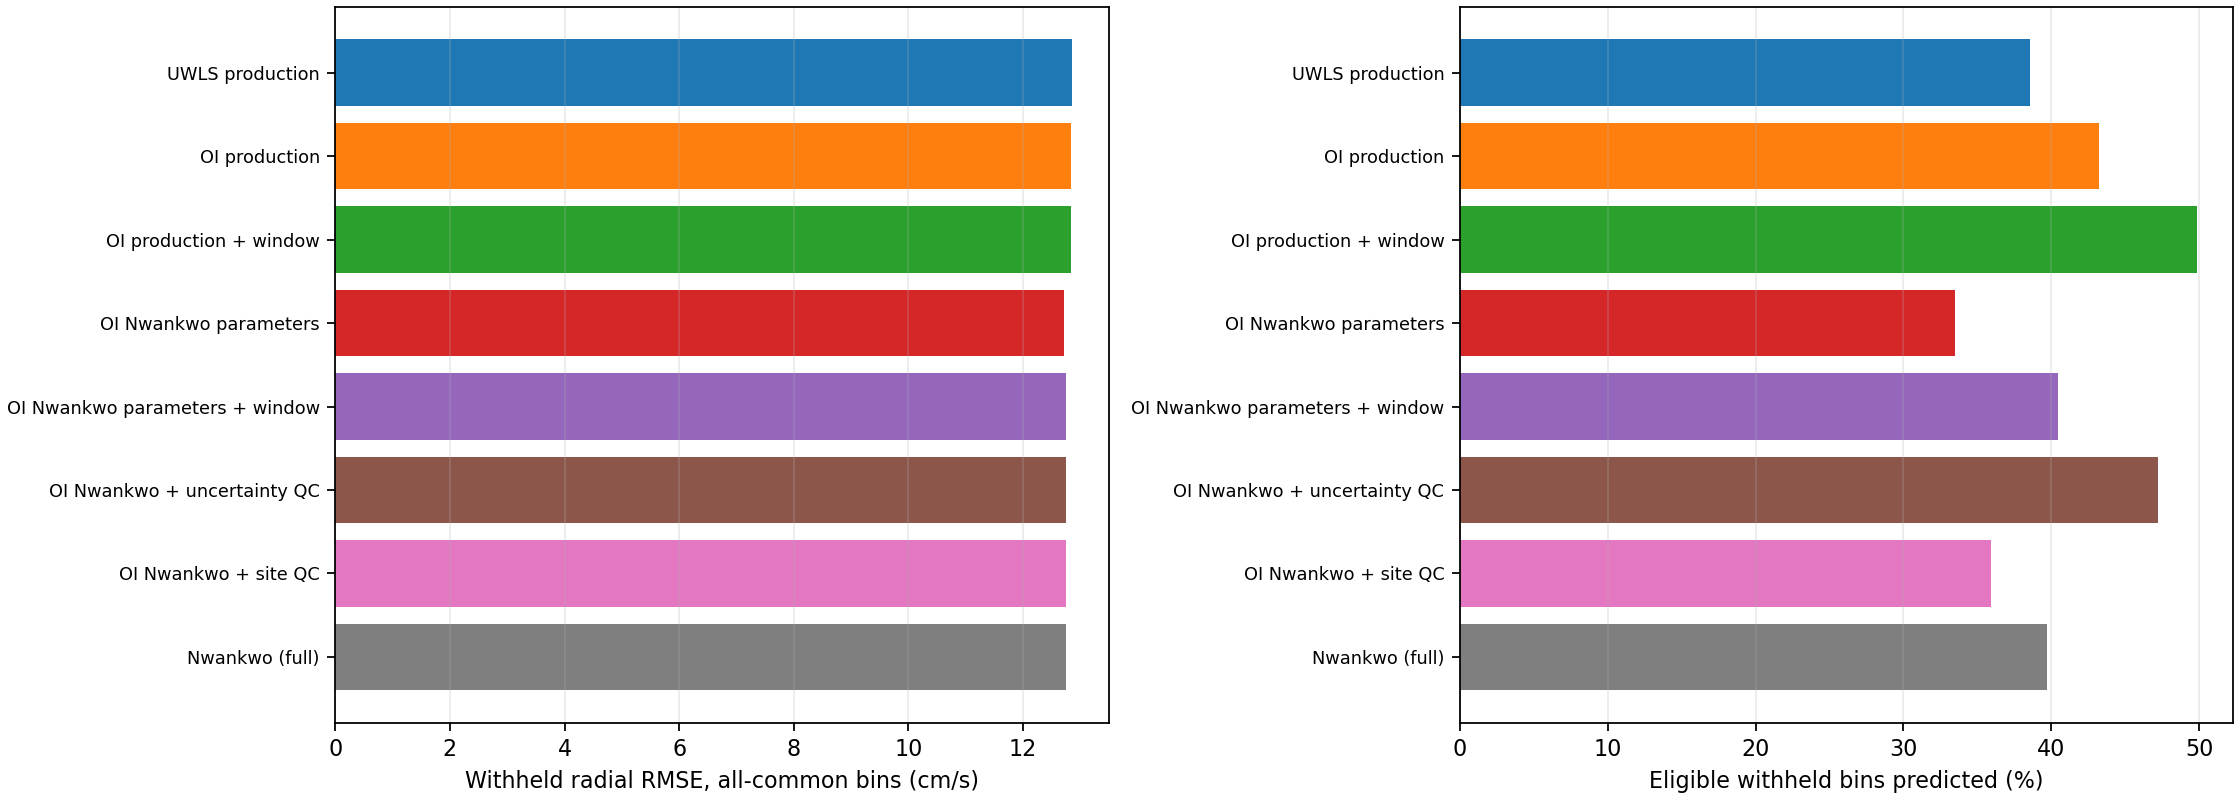

In [3]:
skill=table('skill', index_col='config')
display(skill[['eligible_bins','predicted_bins','coverage_pct','all_common_bins','all_common_rmse_cm_s',
               'bias_cm_s','median_abs_error_cm_s']].round(3))
figure('accuracy_coverage')

## 4. Paired improvements and uncertainty

Each candidate is compared with production OI on its exact common observations. Negative RMSE differences favor the
candidate. Bootstrap intervals resample whole 24-hour blocks, keeping sites and nearby bins together. The 48-hour
sensitivity check uses fewer blocks. Seven days are too few for a strong generalization across seasons or conditions.
These are exploratory intervals across multiple prespecified comparisons, without a multiple-comparison correction.

,paired_bins,paired_rmse_cm_s,baseline_paired_rmse_cm_s,delta_rmse_cm_s,delta_ci_low_24h,delta_ci_high_24h,delta_ci_low_48h,delta_ci_high_48h
config,,,,,,,,
UWLS production,68115,13.872,13.498,0.375,0.254,0.649,0.272,0.500
OI production,78040,14.246,14.246,0.000,0.000,0.000,0.000,0.000
OI production + window,78040,14.545,14.246,0.299,0.228,0.391,0.219,0.383
OI Nwankwo parameters,60474,13.369,13.579,-0.210,-0.355,-0.128,-0.284,-0.113
OI Nwankwo parameters + window,69962,13.865,13.921,-0.056,-0.153,0.001,-0.130,0.016
OI Nwankwo + uncertainty QC,77191,14.128,14.229,-0.100,-0.221,-0.026,-0.187,-0.002
OI Nwankwo + site QC,63169,13.164,13.276,-0.113,-0.270,-0.037,-0.218,-0.011
Nwankwo (full),67888,13.349,13.509,-0.160,-0.342,-0.068,-0.279,-0.041


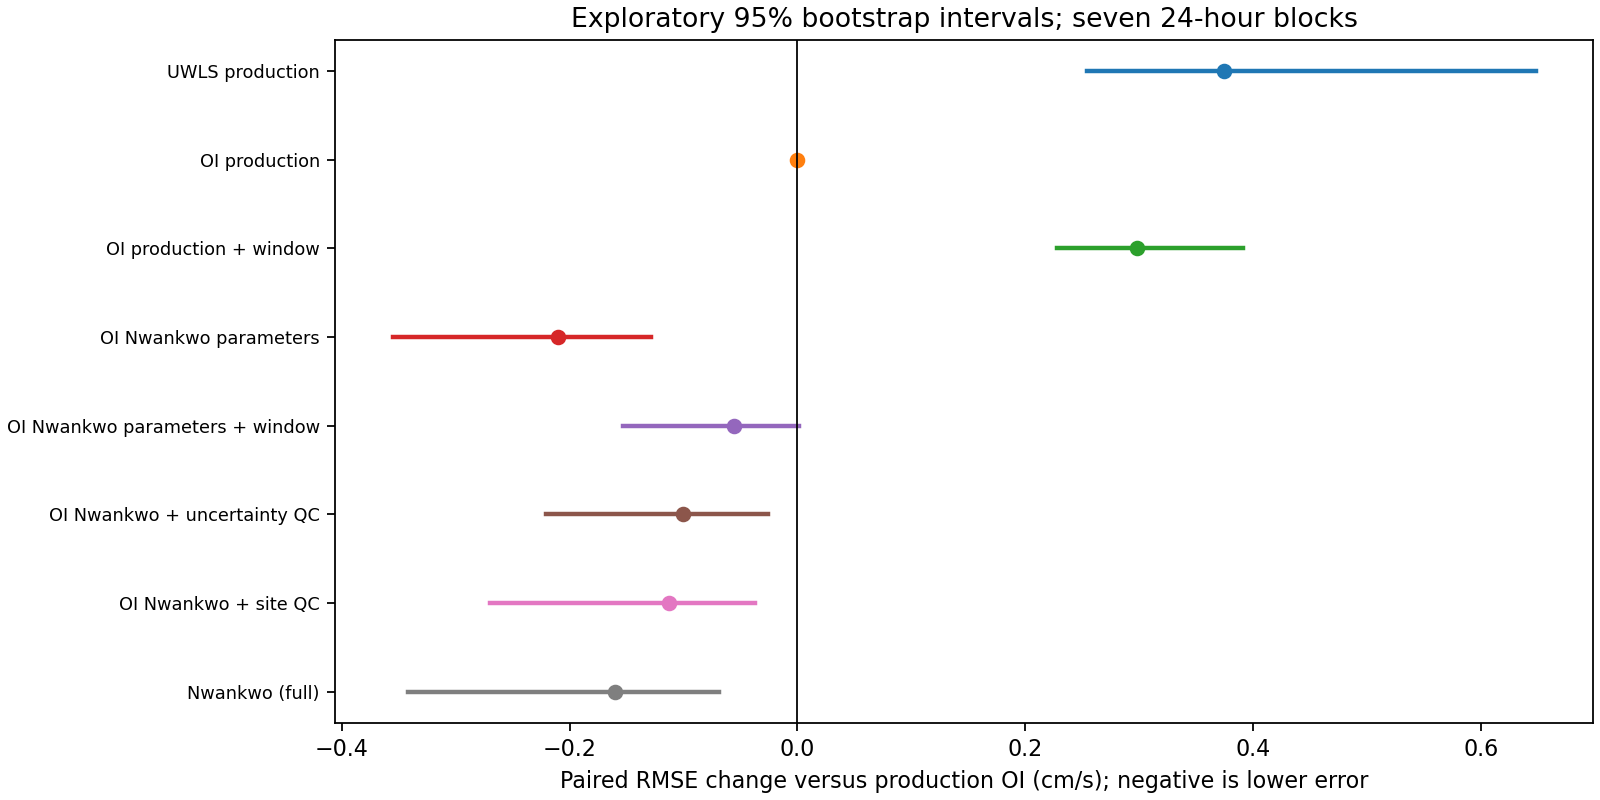

,reference,candidate,paired_bins,delta_rmse_cm_s,ci_low,ci_high,delta_coverage_pp
change,,,,,,,
Add time window,OI production,OI production + window,78040,0.299,0.228,0.391,6.617
Change OI parameters,OI production,OI Nwankwo parameters,60474,-0.210,-0.355,-0.128,-9.727
Add window to revised parameters,OI Nwankwo parameters,OI Nwankwo parameters + window,60474,0.134,0.065,0.186,6.983
Relax uncertainty 0.6 to 0.7,OI Nwankwo parameters + window,OI Nwankwo + uncertainty QC,73086,0.000,0.000,0.000,6.740
Add site-share limit,OI Nwankwo parameters + window,OI Nwankwo + site QC,64928,0.000,0.000,0.000,-4.517
Add share limit after relaxed uncertainty,OI Nwankwo + uncertainty QC,Nwankwo (full),71727,0.000,0.000,0.000,-7.492


Sensitivity: only hours with all three neighboring input hours available


,paired_bins,delta_rmse_cm_s,delta_ci_low_24h,delta_ci_high_24h
config,,,,
UWLS production,65784,0.372,0.243,0.649
OI production,75454,0.000,0.000,0.000
OI production + window,75454,0.295,0.221,0.391
OI Nwankwo parameters,58359,-0.214,-0.360,-0.129
OI Nwankwo parameters + window,67683,-0.062,-0.159,0.001
OI Nwankwo + uncertainty QC,74659,-0.112,-0.228,-0.027
OI Nwankwo + site QC,61062,-0.120,-0.284,-0.039
Nwankwo (full),65611,-0.169,-0.360,-0.071


,time,previous_sites,current_sites,next_sites,complete_window
0,2026-10-06 00:00:00,0,13,13,False
167,2026-10-12 23:00:00,13,13,0,False


In [4]:
display(skill[['paired_bins','paired_rmse_cm_s','baseline_paired_rmse_cm_s','delta_rmse_cm_s',
               'delta_ci_low_24h','delta_ci_high_24h','delta_ci_low_48h','delta_ci_high_48h']].round(3))
figure('paired_improvement')
display(table('ablations').set_index('change').round(3))
print('Sensitivity: only hours with all three neighboring input hours available')
display(table('skill_complete_windows', index_col='config')[['paired_bins','delta_rmse_cm_s','delta_ci_low_24h','delta_ci_high_24h']].round(3))
display(table('window_availability').query('not complete_window'))


## 5. Does one site or day drive the result?

These plots use paired observations against production OI within each site/day. Check agreement in direction across
locations and dates rather than treating the pooled result as universally applicable.

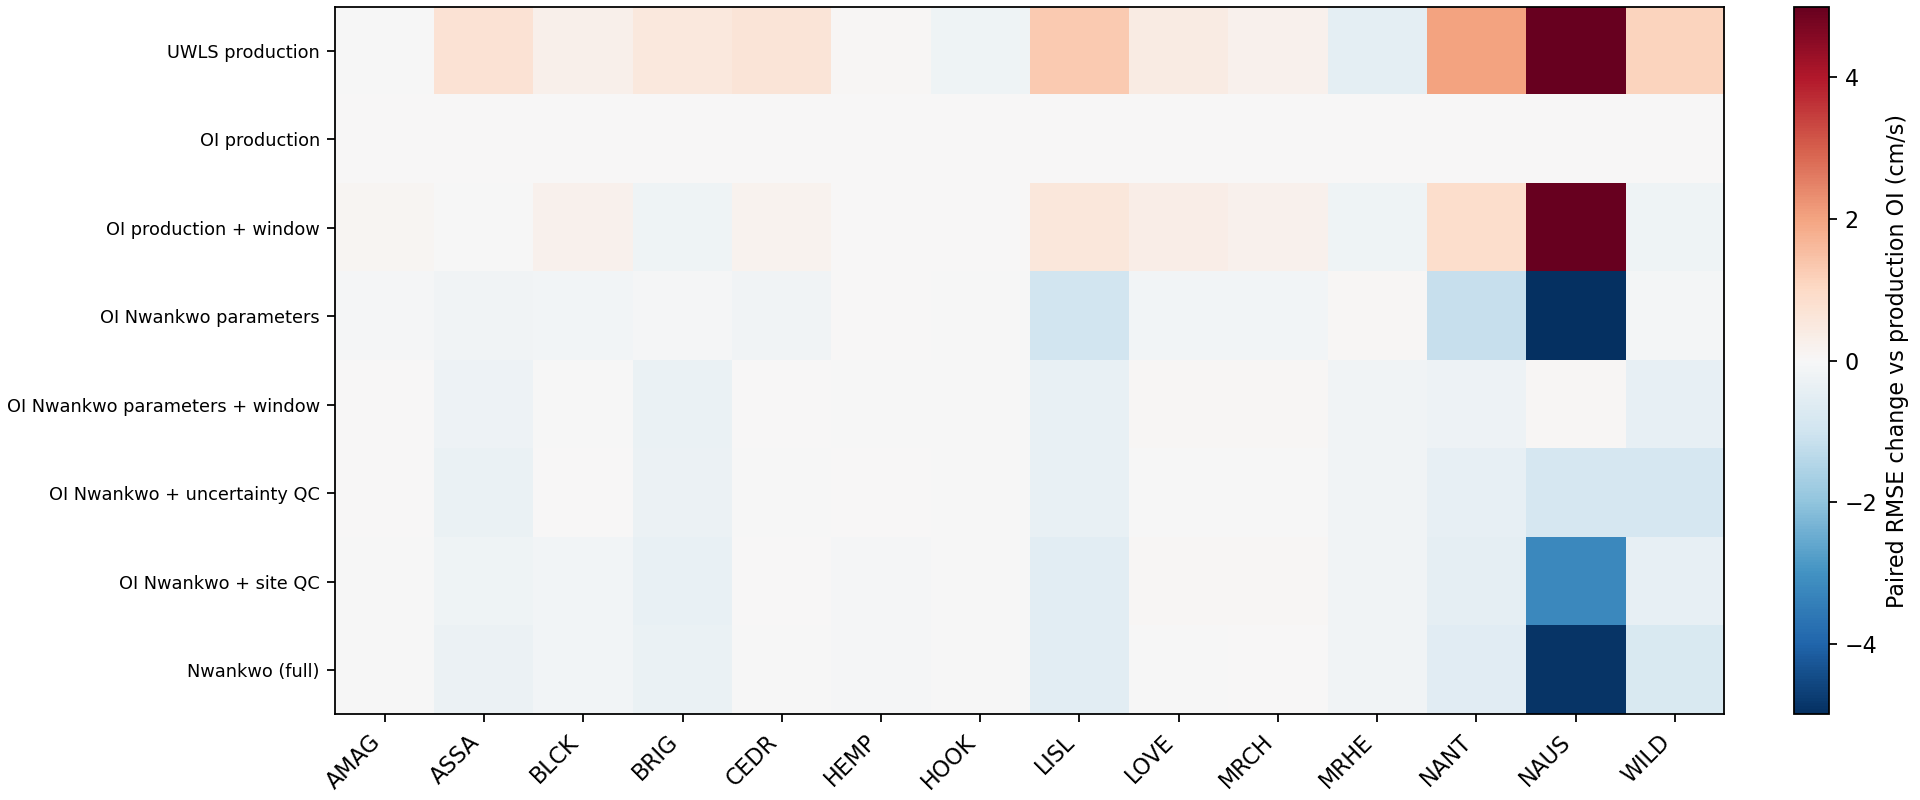

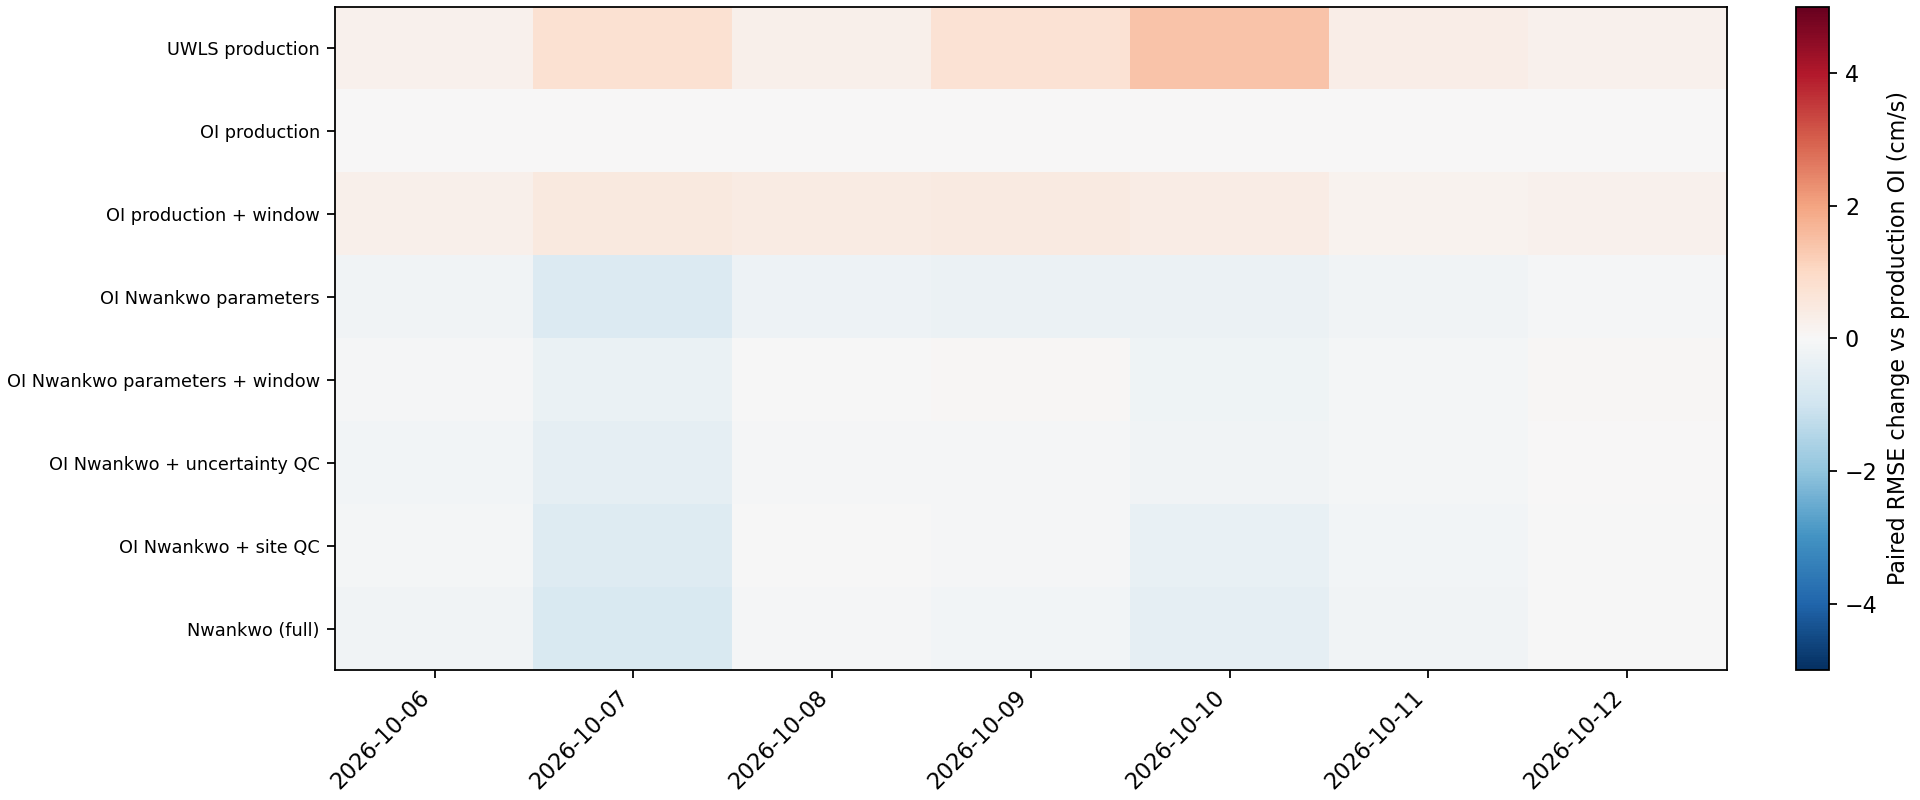

,config,group,label,bins,rmse_cm_s,baseline_rmse_cm_s,delta_rmse_cm_s,bias_cm_s
0,UWLS production,site,AMAG,11004,12.517,12.520,-0.004,0.529
1,UWLS production,site,ASSA,4672,14.122,13.396,0.726,0.398
2,UWLS production,site,BLCK,10332,15.933,15.675,0.257,-0.984
3,UWLS production,site,BRIG,4309,14.406,13.897,0.509,-0.505
4,UWLS production,site,CEDR,4770,13.797,13.135,0.662,0.056
...,...,...,...,...,...,...,...,...
163,Nwankwo (full),day,2026-10-08 00:00:00,12995,12.094,12.138,-0.044,0.225
164,Nwankwo (full),day,2026-10-09 00:00:00,4995,13.548,13.666,-0.118,-0.157
165,Nwankwo (full),day,2026-10-10 00:00:00,2688,16.182,16.635,-0.453,-0.389
166,Nwankwo (full),day,2026-10-11 00:00:00,10864,13.923,14.095,-0.172,-0.537


In [5]:
figure('error_by_site')
figure('error_by_day')
display(table('skill_by_group').round(3))

## 6. Full-network coverage and QC

Hourly totals use the full available network. Coverage, modeled uncertainty, and agreement with production are useful
diagnostics, but none is an independent demonstration of improved accuracy.

,computed_per_hour,pass_per_hour,qc_removed_pct,ever_covered,covered_half_the_time
config,,,,,
UWLS production,4078.95,2978.70,26.97,4961,3308
OI production,5795.65,3436.83,40.70,5723,3775
OI production + window,6275.39,4090.29,34.82,6041,4403
OI Nwankwo parameters,5091.21,2523.31,50.44,4557,2774
OI Nwankwo parameters + window,5596.61,3120.80,44.24,4870,3453
OI Nwankwo + uncertainty QC,5596.61,3790.74,32.27,5670,4136
OI Nwankwo + site QC,5596.61,2738.86,51.06,4748,3047
Nwankwo (full),5596.61,3189.04,43.02,5478,3530


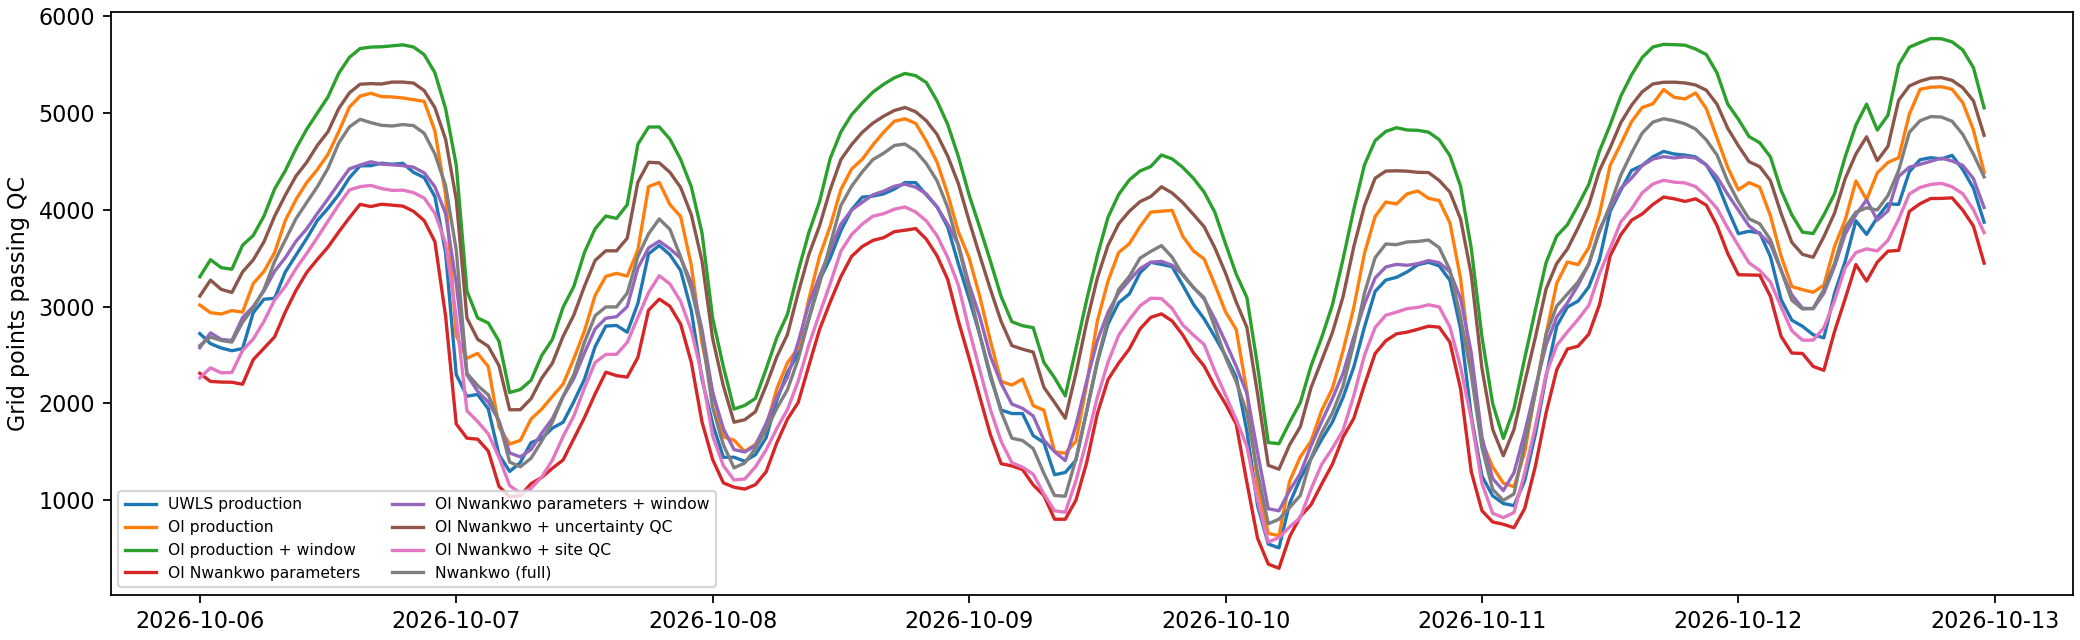

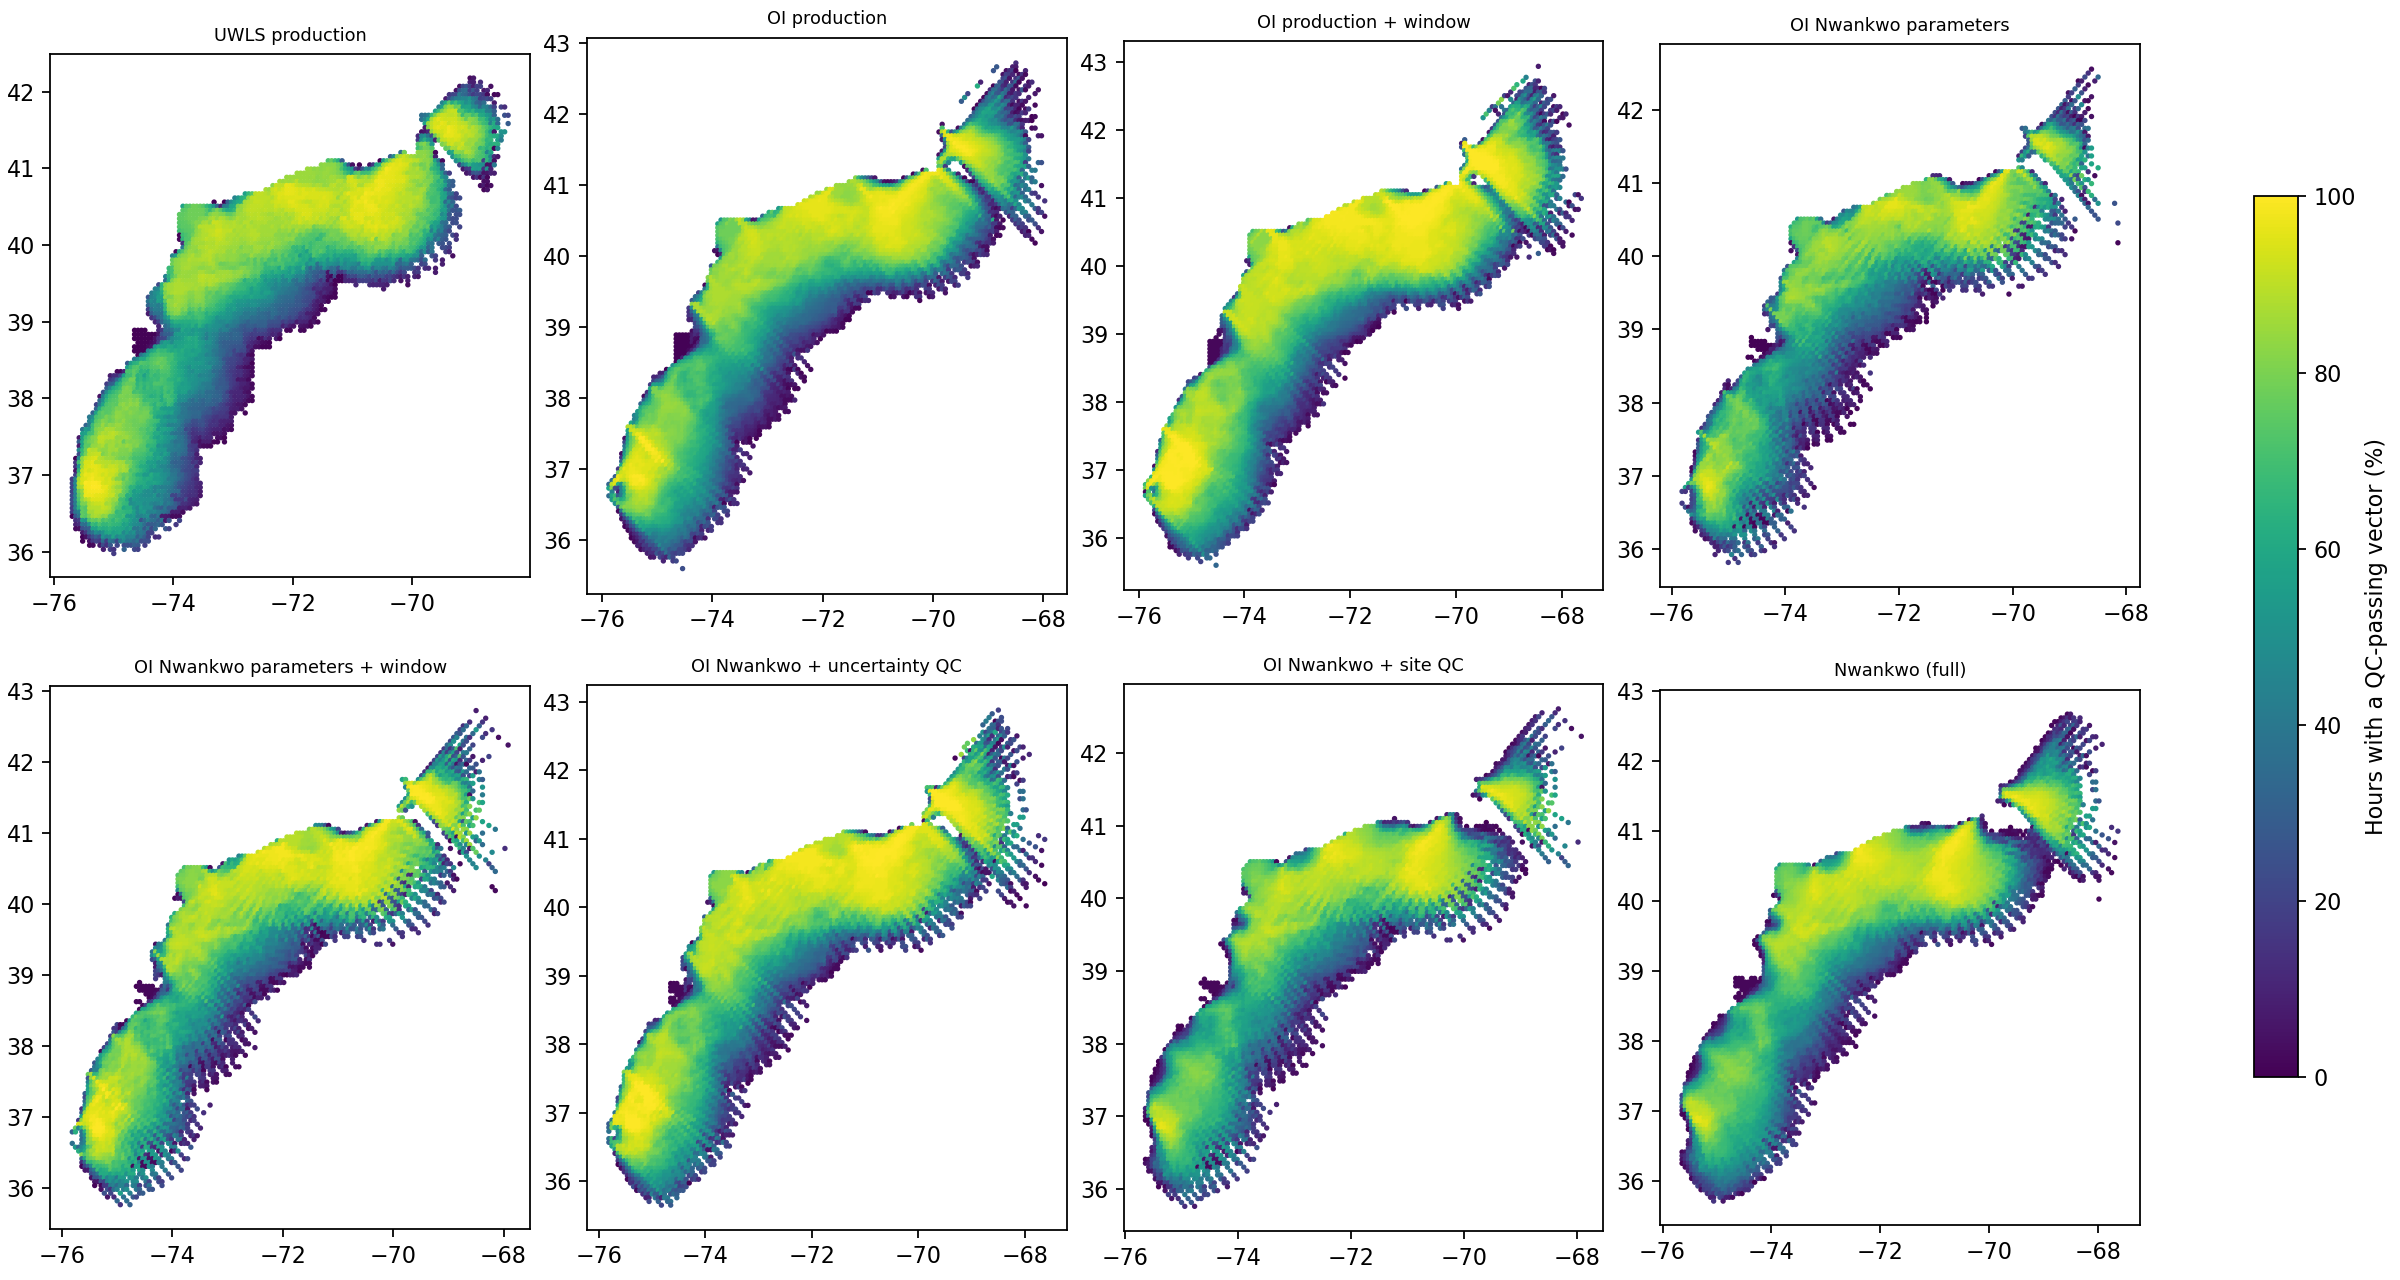

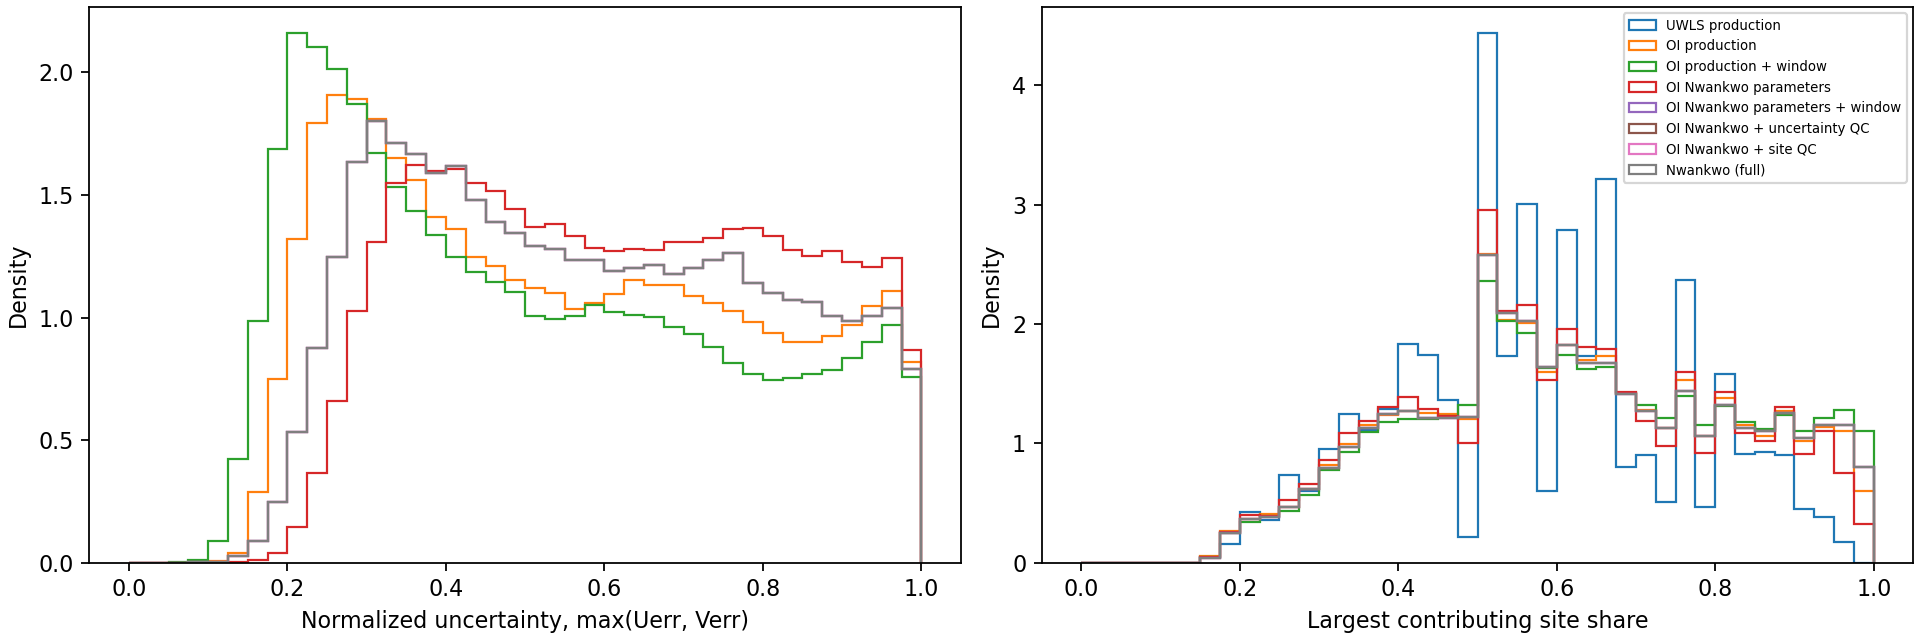

,config,reference,paired_vectors,rms_vector_difference_cm_s
0,UWLS production,OI production,490983,6.242
1,UWLS production,UWLS production,500421,0.000
2,OI production,OI production,577388,0.000
3,OI production,UWLS production,490983,6.242
4,OI production + window,OI production,577388,6.023
5,OI production + window,UWLS production,498307,8.383
6,OI Nwankwo parameters,OI production,423916,1.885
7,OI Nwankwo parameters,UWLS production,408776,6.202
8,OI Nwankwo parameters + window,OI production,501532,6.063
9,OI Nwankwo parameters + window,UWLS production,458934,8.372


In [6]:
display(table('coverage', index_col='config').round(2))
figure('hourly_coverage')
figure('coverage_maps')
figure('uncertainty_site_share')
display(table('production_agreement').round(3))

## 7. Reconstruct hidden daily values

Daily means require at least 12 QC-passing hourly vectors. The same masks hide values observed by production UWLS,
production OI, and the full candidate. Five deterministic repeats test random 10% holes, spatial patches, complete
two-day outages, and two-day spatial patches. Hidden values are removed before fitting means or filling gaps.

Compare recovery **and** vector RMSE. Paired errors use the same recovered points for each method and its reference.
Temporal linear interpolation requires bracketing observations within three days; it does not extrapolate.

Gauss–Markov retains the toolbox's four-hour scale and eight-hour neighbor window, informed by
[Nwankwo et al. (2023), Appendix A](https://doi.org/10.1029/2022JC019055). On daily data the eight-hour window admits
only same-day neighbors. This tests the supplied settings without tuning them. These retrospective fills are estimates
of radar-derived daily values; they are not independent ocean measurements. Repeated masks overlap.

In [7]:
gaps=table('gapfill_summary')
cols=['config','gap','method','reference','hidden','filled','recovered_pct','rmse_cm_s',
      'paired','paired_rmse_cm_s','reference_rmse_cm_s','delta_rmse_cm_s']
display(gaps.loc[gaps.reference == 'linear_time',cols].round(3))
# Incremental benefit of Gauss–Markov over nearest-neighbor filling:
display(gaps.loc[(gaps.reference == 'nearest_neighbor') &
                 (gaps.method == 'nearest_plus_gauss_markov'),cols].round(3))
print('Filled daily NetCDF files:', [p.name for p in RUN.glob('daily_*.nc')])

,config,gap,method,reference,hidden,filled,recovered_pct,rmse_cm_s,paired,paired_rmse_cm_s,reference_rmse_cm_s,delta_rmse_cm_s
0,Nwankwo (full),random_10pct,linear_time,linear_time,9957,5144,51.662,10.606,5144,10.606,10.606,0.000
2,Nwankwo (full),random_10pct,nearest_neighbor,linear_time,9957,9956,99.990,7.694,5144,7.159,10.606,-3.446
4,Nwankwo (full),random_10pct,nearest_plus_gauss_markov,linear_time,9957,9957,100.000,7.694,5144,7.159,10.606,-3.446
6,Nwankwo (full),space_time_patch,linear_time,linear_time,2035,1971,96.855,10.078,1971,10.078,10.078,0.000
8,Nwankwo (full),space_time_patch,nearest_neighbor,linear_time,2035,2024,99.459,9.210,1971,9.175,10.078,-0.903
10,Nwankwo (full),space_time_patch,nearest_plus_gauss_markov,linear_time,2035,2032,99.853,9.206,1971,9.175,10.078,-0.903
12,Nwankwo (full),spatial_patches,linear_time,linear_time,3824,2364,61.820,10.652,2364,10.652,10.652,0.000
14,Nwankwo (full),spatial_patches,nearest_neighbor,linear_time,3824,3740,97.803,10.661,2364,9.564,10.652,-1.089
16,Nwankwo (full),spatial_patches,nearest_plus_gauss_markov,linear_time,3824,3823,99.974,10.576,2364,9.564,10.652,-1.089
18,Nwankwo (full),two_day_outage,linear_time,linear_time,22559,19582,86.803,11.490,19582,11.490,11.490,0.000


,config,gap,method,reference,hidden,filled,recovered_pct,rmse_cm_s,paired,paired_rmse_cm_s,reference_rmse_cm_s,delta_rmse_cm_s
5,Nwankwo (full),random_10pct,nearest_plus_gauss_markov,nearest_neighbor,9957,9957,100.000,7.694,9956,7.694,7.694,0.0
11,Nwankwo (full),space_time_patch,nearest_plus_gauss_markov,nearest_neighbor,2035,2032,99.853,9.206,2024,9.210,9.210,0.0
17,Nwankwo (full),spatial_patches,nearest_plus_gauss_markov,nearest_neighbor,3824,3823,99.974,10.576,3740,10.661,10.661,0.0
23,Nwankwo (full),two_day_outage,nearest_plus_gauss_markov,nearest_neighbor,22559,22374,99.180,13.583,22232,13.601,13.601,0.0
29,OI production,random_10pct,nearest_plus_gauss_markov,nearest_neighbor,9957,9955,99.980,7.360,9954,7.360,7.360,0.0
35,OI production,space_time_patch,nearest_plus_gauss_markov,nearest_neighbor,2035,2035,100.000,8.920,2035,8.920,8.920,0.0
41,OI production,spatial_patches,nearest_plus_gauss_markov,nearest_neighbor,3824,3824,100.000,10.309,3726,10.422,10.422,0.0
47,OI production,two_day_outage,nearest_plus_gauss_markov,nearest_neighbor,22559,22491,99.699,12.808,22436,12.815,12.815,0.0
53,UWLS production,random_10pct,nearest_plus_gauss_markov,nearest_neighbor,9957,9946,99.890,7.693,9929,7.684,7.684,0.0
59,UWLS production,space_time_patch,nearest_plus_gauss_markov,nearest_neighbor,2035,2035,100.000,9.390,2033,9.386,9.386,0.0


Filled daily NetCDF files: ['daily_Nwankwo_(full).nc', 'daily_UWLS_production.nc', 'daily_OI_production.nc']


## 8. Independent validation and an additional week

Independent validation accepts quality-controlled current components with explicit units. Match comparable observing
depths and averaging periods before interpreting the comparison. Sampling uses the nearest grid point within 4.3 km
and time within 30 minutes; every configuration is scored on the same independent samples.

A second archived week can be evaluated with the same CLI and frozen parameters using `--data`, `--start`, and `--end`.
Do not use its results to retune parameters and continue describing it as an untouched validation set.

In [8]:
status=json.loads((RUN / 'independent_validation.json').read_text())
display(status)
if status['status'] == 'complete':
    display(table('independent_validation').round(3))
print('Additional-week validation: pending; only the supplied week was available.')

{'status': 'not_run',
 'reason': 'No independent buoy/drifter observations supplied'}

Additional-week validation: pending; only the supplied week was available.


## 9. Findings and reproducibility

The report records measured results and their limits. It does not presume that the proposed processing wins.
The complete paired predictions, per-day/per-site summaries, gap-test repeats, figures, and daily fields are available
next to the report. Computed fill values carry flags and are masked outside the water grid.

In [9]:
report=(RUN / 'report.md').read_text()
# Figures have already been displayed above; keep this cell focused on the report text.
display(Markdown('\n'.join(line for line in report.splitlines() if not line.startswith('!['))))
print('Report:', RUN / 'report.md')

# MARACOOS processing comparison

Evaluation: 2026-10-06 00:00:00 through 2026-10-12 23:00:00. Fingerprint: `3dc6274a28e6d79b`.

This is a fixed-configuration, one-week exploratory evaluation. No parameters were tuned on these observations.
Independent buoy/drifter validation: **pending: data not supplied**. An untouched additional week is **pending: data not supplied**.

## Measured result for the full candidate

- Withheld-radial coverage: **39.72%**, versus **43.21%** for production OI.
- On the same **67,888** withheld observations, RMSE is **13.349 cm/s**, versus
  **13.509 cm/s** for production OI.
- Candidate minus production RMSE: **-0.160 cm/s**; exploratory 24-hour-block 95% interval
  **[-0.342, -0.068]**. The 48-hour-block interval is
  **[-0.279, -0.041] cm/s**.

These numbers describe this week and this withheld-radar test. A negative difference means lower error, a positive
difference means higher error; the interval and coverage tradeoff must be considered together.

The parameter candidates follow the existing study notebook, informed by
[Nwankwo et al. (2026)](https://doi.org/10.1007/s10236-026-01813-8).
Values 625 and 100 are used in the native squared-cm/s units of these radials, as in the supplied notebook;
the publication labels its variances m²/s², so this is an explicit study assumption, not a verified unit correction.
The gap-filling scales come from [Nwankwo et al. (2023), Appendix A](https://doi.org/10.1029/2022JC019055).

## Production baseline check

Compared this run's production OI u, v and primary QC with the published NetCDF at the study grid,
including matching missingness. Velocities are compared after the production float32/whole-cm/s rounding.
Total mismatched entries: **0**. See `tables/production_parity.csv` for all hours.

## Withheld-site prediction

Each available site is excluded from **every hour** of the input window. Its cleaned radial observations are predicted
from the remaining sites at the nearest grid point within 4.3 km. The interval between tested hours is six hours by
default (see manifest). A whole site/time/bin identity is used to align every comparison. These targets are other
radar observations, not independent truth; shared errors and representativeness differences can remain.

All-common RMSE uses observations predicted by all eight configurations. Paired RMSE and its difference use each
candidate's overlap with production OI. Coverage uses all finite withheld observations within the grid-distance limit.
Intervals resample whole 24-hour blocks across all sites; 48-hour sensitivity intervals are in the CSV. With only seven
days, both are exploratory, not evidence of general performance across seasons or conditions.
The intervals are not adjusted for the multiple prespecified comparisons.
The archive has no radials outside this week: the first and last full-network hours have shortened windows.
`tables/window_availability.csv` records the available sites in every neighboring hour;
`tables/skill_complete_windows.csv` repeats the skill comparison only where all three input hours are available.

| config | coverage_pct | all_common_rmse_cm_s | paired_rmse_cm_s | baseline_paired_rmse_cm_s | delta_rmse_cm_s | delta_ci_low_24h | delta_ci_high_24h |
| --- | --- | --- | --- | --- | --- | --- | --- |
| UWLS production | 38.578 | 12.857 | 13.872 | 13.498 | 0.375 | 0.254 | 0.649 |
| OI production | 43.212 | 12.832 | 14.246 | 14.246 | 0.000 | 0.000 | 0.000 |
| OI production + window | 49.829 | 12.845 | 14.545 | 14.246 | 0.299 | 0.228 | 0.391 |
| OI Nwankwo parameters | 33.485 | 12.723 | 13.369 | 13.579 | -0.210 | -0.355 | -0.128 |
| OI Nwankwo parameters + window | 40.469 | 12.759 | 13.865 | 13.921 | -0.056 | -0.153 | 0.001 |
| OI Nwankwo + uncertainty QC | 47.208 | 12.759 | 14.128 | 14.229 | -0.100 | -0.221 | -0.026 |
| OI Nwankwo + site QC | 35.951 | 12.759 | 13.164 | 13.276 | -0.113 | -0.270 | -0.037 |
| Nwankwo (full) | 39.716 | 12.759 | 13.349 | 13.509 | -0.160 | -0.342 | -0.068 |


## Which change matters?

Negative RMSE differences mean lower prediction error on the *same* observations. QC-only changes can leave common-bin
RMSE unchanged while changing which observations are accepted; that is selection, not improved velocity estimates.
Raising the normalized-uncertainty limit from 0.6 to 0.7 relaxes it. Adding a site-share limit is a separate restriction.

| change | delta_rmse_cm_s | ci_low | ci_high | delta_coverage_pp | paired_bins |
| --- | --- | --- | --- | --- | --- |
| Add time window | 0.299 | 0.228 | 0.391 | 6.617 | 78040 |
| Change OI parameters | -0.210 | -0.355 | -0.128 | -9.727 | 60474 |
| Add window to revised parameters | 0.134 | 0.065 | 0.186 | 6.983 | 60474 |
| Relax uncertainty 0.6 to 0.7 | 0.000 | 0.000 | 0.000 | 6.740 | 73086 |
| Add site-share limit | 0.000 | 0.000 | 0.000 | -4.517 | 64928 |
| Add share limit after relaxed uncertainty | 0.000 | 0.000 | 0.000 | -7.492 | 71727 |

## Full-network coverage

| config | computed_per_hour | pass_per_hour | qc_removed_pct | ever_covered |
| --- | --- | --- | --- | --- |
| UWLS production | 4078.952 | 2978.696 | 26.974 | 4961 |
| OI production | 5795.649 | 3436.833 | 40.700 | 5723 |
| OI production + window | 6275.387 | 4090.286 | 34.820 | 6041 |
| OI Nwankwo parameters | 5091.208 | 2523.310 | 50.438 | 4557 |
| OI Nwankwo parameters + window | 5596.607 | 3120.798 | 44.238 | 4870 |
| OI Nwankwo + uncertainty QC | 5596.607 | 3790.744 | 32.267 | 5670 |
| OI Nwankwo + site QC | 5596.607 | 2738.863 | 51.062 | 4748 |
| Nwankwo (full) | 5596.607 | 3189.042 | 43.018 | 5478 |


## Gap reconstruction

Daily fields require at least 12 QC-passing hourly vectors. Identical masks hide values observed by all three fields.
Five deterministic repeats test random 10% holes, 5x5-cell spatial patches, two-day outages, and two-day spatial patches.
Original hidden values are removed **before** means or fills are computed. Methods: linear temporal interpolation
(bracketing observations, maximum three-day span), nearest-neighbor averaging, and nearest-neighbor plus Gauss-Markov.
Recovery and vector RMSE are both reported; paired differences use the same recovered points.

These tests measure recovery of radar-derived daily values, not accuracy against the ocean. Repeats overlap and are
not independent samples. Gauss-Markov uses the toolbox's unchanged 4-hour scale and 8-hour search limit: on daily data,
its neighbor search uses the same day only. No temporal-scale tuning was performed. Exported fills are flagged and
masked outside the study's water grid. See `tables/gapfill_summary.csv` and `tables/gapfill_repeats.csv`.

For the full candidate's daily field, each row below compares a fill method with linear temporal interpolation
on exactly the same recovered hidden values. Errors are vector RMSE in cm/s; recovery is a percentage of hidden values.

| gap | method | recovered_pct | paired_rmse_cm_s | reference_rmse_cm_s | delta_rmse_cm_s |
| --- | --- | --- | --- | --- | --- |
| random_10pct | linear_time | 51.662 | 10.606 | 10.606 | 0.000 |
| random_10pct | nearest_neighbor | 99.990 | 7.159 | 10.606 | -3.446 |
| random_10pct | nearest_plus_gauss_markov | 100.000 | 7.159 | 10.606 | -3.446 |
| space_time_patch | linear_time | 96.855 | 10.078 | 10.078 | 0.000 |
| space_time_patch | nearest_neighbor | 99.459 | 9.175 | 10.078 | -0.903 |
| space_time_patch | nearest_plus_gauss_markov | 99.853 | 9.175 | 10.078 | -0.903 |
| spatial_patches | linear_time | 61.820 | 10.652 | 10.652 | 0.000 |
| spatial_patches | nearest_neighbor | 97.803 | 9.564 | 10.652 | -1.089 |
| spatial_patches | nearest_plus_gauss_markov | 99.974 | 9.564 | 10.652 | -1.089 |
| two_day_outage | linear_time | 86.803 | 11.490 | 11.490 | 0.000 |
| two_day_outage | nearest_neighbor | 98.550 | 12.538 | 11.488 | 1.050 |
| two_day_outage | nearest_plus_gauss_markov | 99.180 | 12.539 | 11.490 | 1.049 |

## Interpretation and operational limits

The study does not assume that a candidate wins. Assess error, retained coverage, consistency by site/day, and both
block sizes together. A centered t-1/t/t+1 window needs one additional hour of radial availability. The gap-filling
methods and temporal interpolation use future observations and are retrospective estimates.

The additional-week test remains unrun; select any candidate using this week, then freeze the parameters before
examining another week. Independent current validation is pending: data not supplied. WLS and EHN algorithms were not changed.

## Reproduction

Run `python examples/maracoos_study.py --data /path/to/2026-10-06_week`. Use `--stage analysis` to rebuild tables/figures
from completed checkpoints. `--start`, `--end`, `--loso-step`, and `--output` select another archived period and output.
The manifest records input checksums, numerical source checksums, configurations and package versions. Computation
checkpoints use atomic replacement and are isolated by fingerprint. Do not compare cached runs without their manifests.

Report: /Users/mikesmith/Documents/github/HFRadarPy/examples/output/maracoos_totals_study/3dc6274a28e6d79b/report.md
